<a href="https://colab.research.google.com/github/ek182238/CSC349/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1

Load the dataset into a Pandas DataFrame.

Explanation: I directly loaded the UCI Heart Disease dataset from the standard repository using fetch_ucirepo. X is the features, and y is the target variable. I concatenated them into a pandas dataframe.

In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

heart_disease = fetch_ucirepo(id=45)

X = heart_disease.data.features
y = heart_disease.data.targets

df = pd.concat([X, y], axis=1)

# Task 2

Use structural inspection methods (`head()`, `info()`, `describe()`) to analyze continuous and categorical features.

Explanation: For the whole dataframe, I used head() to inspect the first 5 rows, info() to check the data types, and describe() to see the shape of the distributions and if any columns have missing values. I noticed that everything is either an int or float, even the categorical columns.

In [ ]:
print(df.head())
print(df.info())
print(df.describe())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  num  
0  0.0   6.0    0  
1  3.0   3.0    2  
2  2.0   7.0    1  
3  0.0   3.0    0  
4  0.0   3.0    0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       

# Task 3

Quantify and handle any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings) and implement a structured imputation strategy using Scikit-Learn's `SimpleImputer`.

Explanation: I replaced "?" values with NaN so that they show up as missing values. For the numerical features, I replaced missing values with their median, and for categorical features, I replaced missing values with the most frequent value.

In [ ]:
from sklearn.impute import SimpleImputer
df = df.replace('?', np.nan)

ca_imputer = SimpleImputer(strategy='median')
df['ca'] = ca_imputer.fit_transform(df[['ca']])

thal_imputer = SimpleImputer(strategy='median')
df['thal'] = ca_imputer.fit_transform(df[['thal']])
print(df.isna().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


# Task 4

Isolate **numerical** and **categorical** features, then build a Scikit-Learn `ColumnTransformer` and `Pipeline` that applies appropriate scaling (`StandardScaler` or `MinMaxScaler`) to numerical columns and encoding (`OneHotEncoder`) to categorical columns.

Explanation: Since the catrgorical data in this dataset is represented by numbers, I checked the variable table on the UCI machine learning repository, where it identified which ones were numerical and which were catrgorical. Using that info, I split the dataset into its numerical and categorical features, using StandardScaler on numerical features and OneHotEncoder on categorical features. I put both of the pipelines through a ColumnTransformer. Then I used train_test_split to do a 80/20 split between training and testing data.

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

X = df.drop(columns='num')
y = (df['num'] > 0).astype(int)

num_features = X[['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']]
cat_features = X[['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']]

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder())
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_features.columns),
    ('cat', cat_pipeline, cat_features.columns)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Task 5

Instantiate and train a **Support Vector Classifier** (`SVC`) configured with `kernel='rbf'` and `probability=True` within your pipeline, then evaluate performance using a **confusion matrix**, **classification report**, and **ROC-AUC curve**.

Explanation: I put a SVC classifier and the preprocessor through a pipeline, and I used that pipeline to fit the training data and predict the last 20% of the target data. Originally, there was a 5x5 confusion matrix because the target variable was a value from 0 to 4. 1 through 4 indicated heart disease. I fixed this by editing a line in task 4 to set any value greater than 0 to 1, so now there are only 2 possible values for the target variable. I evaluated performance using a classification report, confusion matrix, and ROC-AUC curve.

              precision    recall  f1-score   support

           0       0.84      0.93      0.89        29
           1       0.93      0.84      0.89        32

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



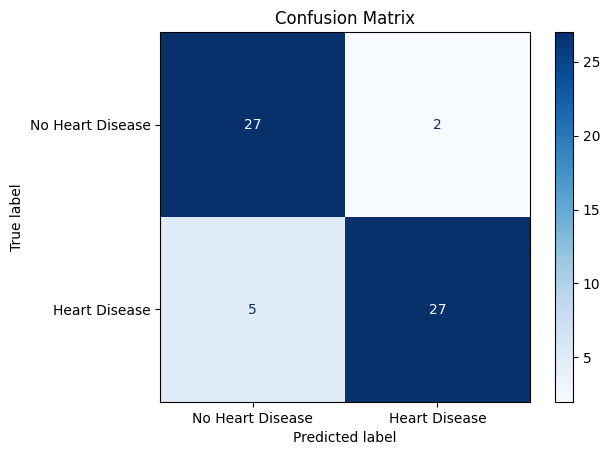

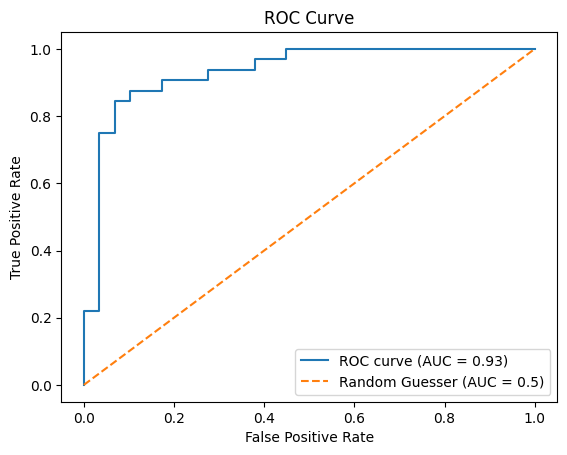

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

svc_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf', probability=True))
])

svc_pipeline.fit(X_train, y_train)
y_pred_svc = svc_pipeline.predict(X_test)
y_proba_svc = svc_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_svc))

ConfusionMatrixDisplay.from_estimator(svc_pipeline,
                                      X_test, y_test,
                                      display_labels=['No Heart Disease', 'Heart Disease'],
                                      cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

auc_score_svc = roc_auc_score(y_test, y_proba_svc)
fpr, tpr, thresholds = roc_curve(y_test, y_proba_svc)

plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc_score_svc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guesser (AUC = 0.5)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

# Task 6

Instantiate and train a **Decision Tree Classifier** (`DecisionTreeClassifier`) within your pipeline, and evaluate its performance using identical metrics to compare against your SVC model.

Explanation: I made a tree pipeline even though scaling isn't necessary for decision trees. I still reused the preprocessor because it already includes imputation and encoding. I evaluated its performance using a classification report, confusion matrix, and ROC-AUC curve. The results were a lot worse for this one than for the SVC model.

              precision    recall  f1-score   support

           0       0.68      0.66      0.67        29
           1       0.70      0.72      0.71        32

    accuracy                           0.69        61
   macro avg       0.69      0.69      0.69        61
weighted avg       0.69      0.69      0.69        61



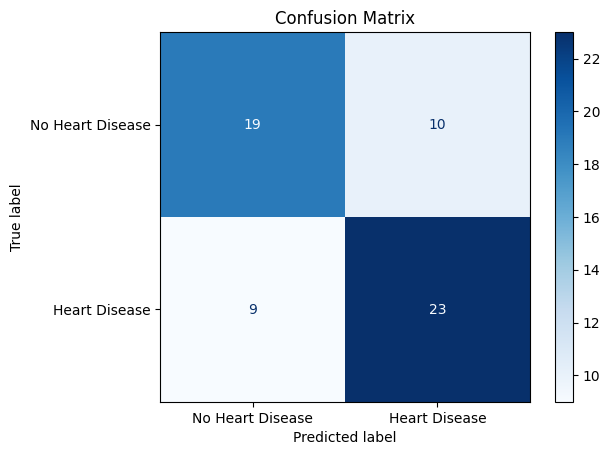

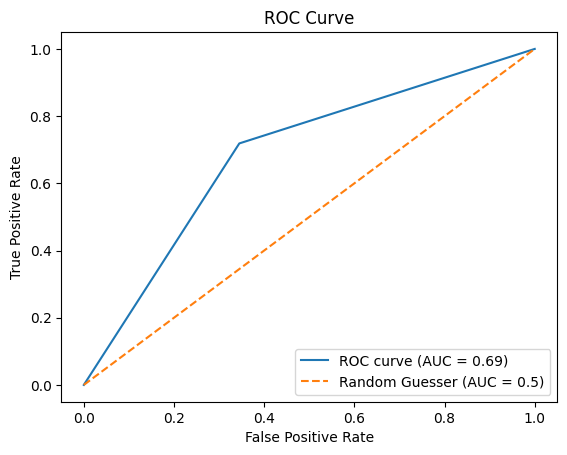

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier())
])

tree_pipeline.fit(X_train, y_train)
y_pred_tree = tree_pipeline.predict(X_test)
y_proba_tree = tree_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_tree))

ConfusionMatrixDisplay.from_estimator(tree_pipeline,
                                      X_test, y_test,
                                      display_labels=['No Heart Disease', 'Heart Disease'],
                                      cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

auc_score_tree = roc_auc_score(y_test, y_proba_tree)
fpr, tpr, thresholds = roc_curve(y_test, y_proba_tree)

plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc_score_tree:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guesser (AUC = 0.5)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

# Task 7

Perform hyperparameter tuning using `GridSearchCV` on your SVC pipeline (exploring parameters such as `C` and `gamma`) to optimize **cross-validation performance**.

Explanation: I used GridSearchCV to test different C and gamma parameters. I adjusted the scoring parameter of GridSearchCV. When it was set to 'accuracy', the best C and gamma values were 1 and 0.01. When I set it to 'roc-auc', the best C and gamma values were 100 and 0.001. I used the accuracy one as the best_svc and evaluated its performance using a classification report, confusion matrix, and ROC-AUC curve. I also printed the cross-validation score.

Best parameters: {'classifier__C': 100, 'classifier__gamma': 0.001}
Best score: 0.9028860028860028
              precision    recall  f1-score   support

           0       0.76      0.90      0.83        29
           1       0.89      0.75      0.81        32

    accuracy                           0.82        61
   macro avg       0.83      0.82      0.82        61
weighted avg       0.83      0.82      0.82        61



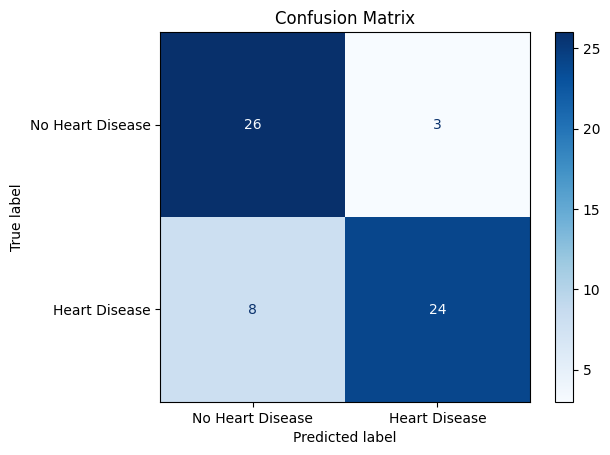

Cross-validation scores: [0.75510204 0.83673469 0.79166667 0.8125     0.8125    ]
Mean cross-validation score: 0.8017006802721088


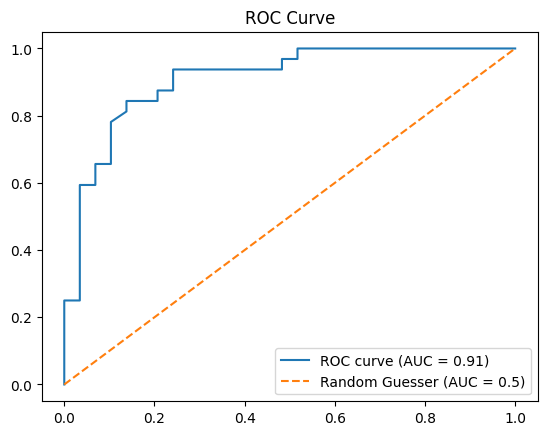

In [ ]:
from sklearn.model_selection import GridSearchCV, cross_val_score

params = {
    'classifier__C': [0.1, 1, 10, 100, 1000],
    'classifier__gamma': [1, 0.1, 0.01, 0.001, 0.0001],
}

grid_search = GridSearchCV(svc_pipeline, params, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print('Best parameters:', grid_search.best_params_)
print('Best score:', grid_search.best_score_)

best_svc = grid_search.best_estimator_

y_pred_best_svc = best_svc.predict(X_test)
y_proba_best_svc = best_svc.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_best_svc))

ConfusionMatrixDisplay.from_estimator(best_svc,
                                      X_test, y_test,
                                      display_labels=['No Heart Disease', 'Heart Disease'],
                                      cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

auc_score_best_svc = roc_auc_score(y_test, y_proba_best_svc)
fpr, tpr, thresholds = roc_curve(y_test, y_proba_best_svc)
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc_score_best_svc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guesser (AUC = 0.5)')
plt.title('ROC Curve')
plt.legend(loc='lower right')

cv_scores = cross_val_score(svc_pipeline, X_train, y_train, cv=5)
print('Cross-validation scores:', cv_scores)
print('Mean cross-validation score:', cv_scores.mean())

# Task 8

Generate a decision tree visualization (`plot_tree`) or inspect feature importances to interpret how the model separates patients with heart disease from healthy patients.

Explanation: I made stored the classifier step of the tree pipeline and a list of the feature names as variables, and I used them to create the plot_tree. Since the tree structure was very large, I adjusted the figsize and fontsize to make the text larger and more readable. I then printed a series of the importances, using the feature names and their importance.

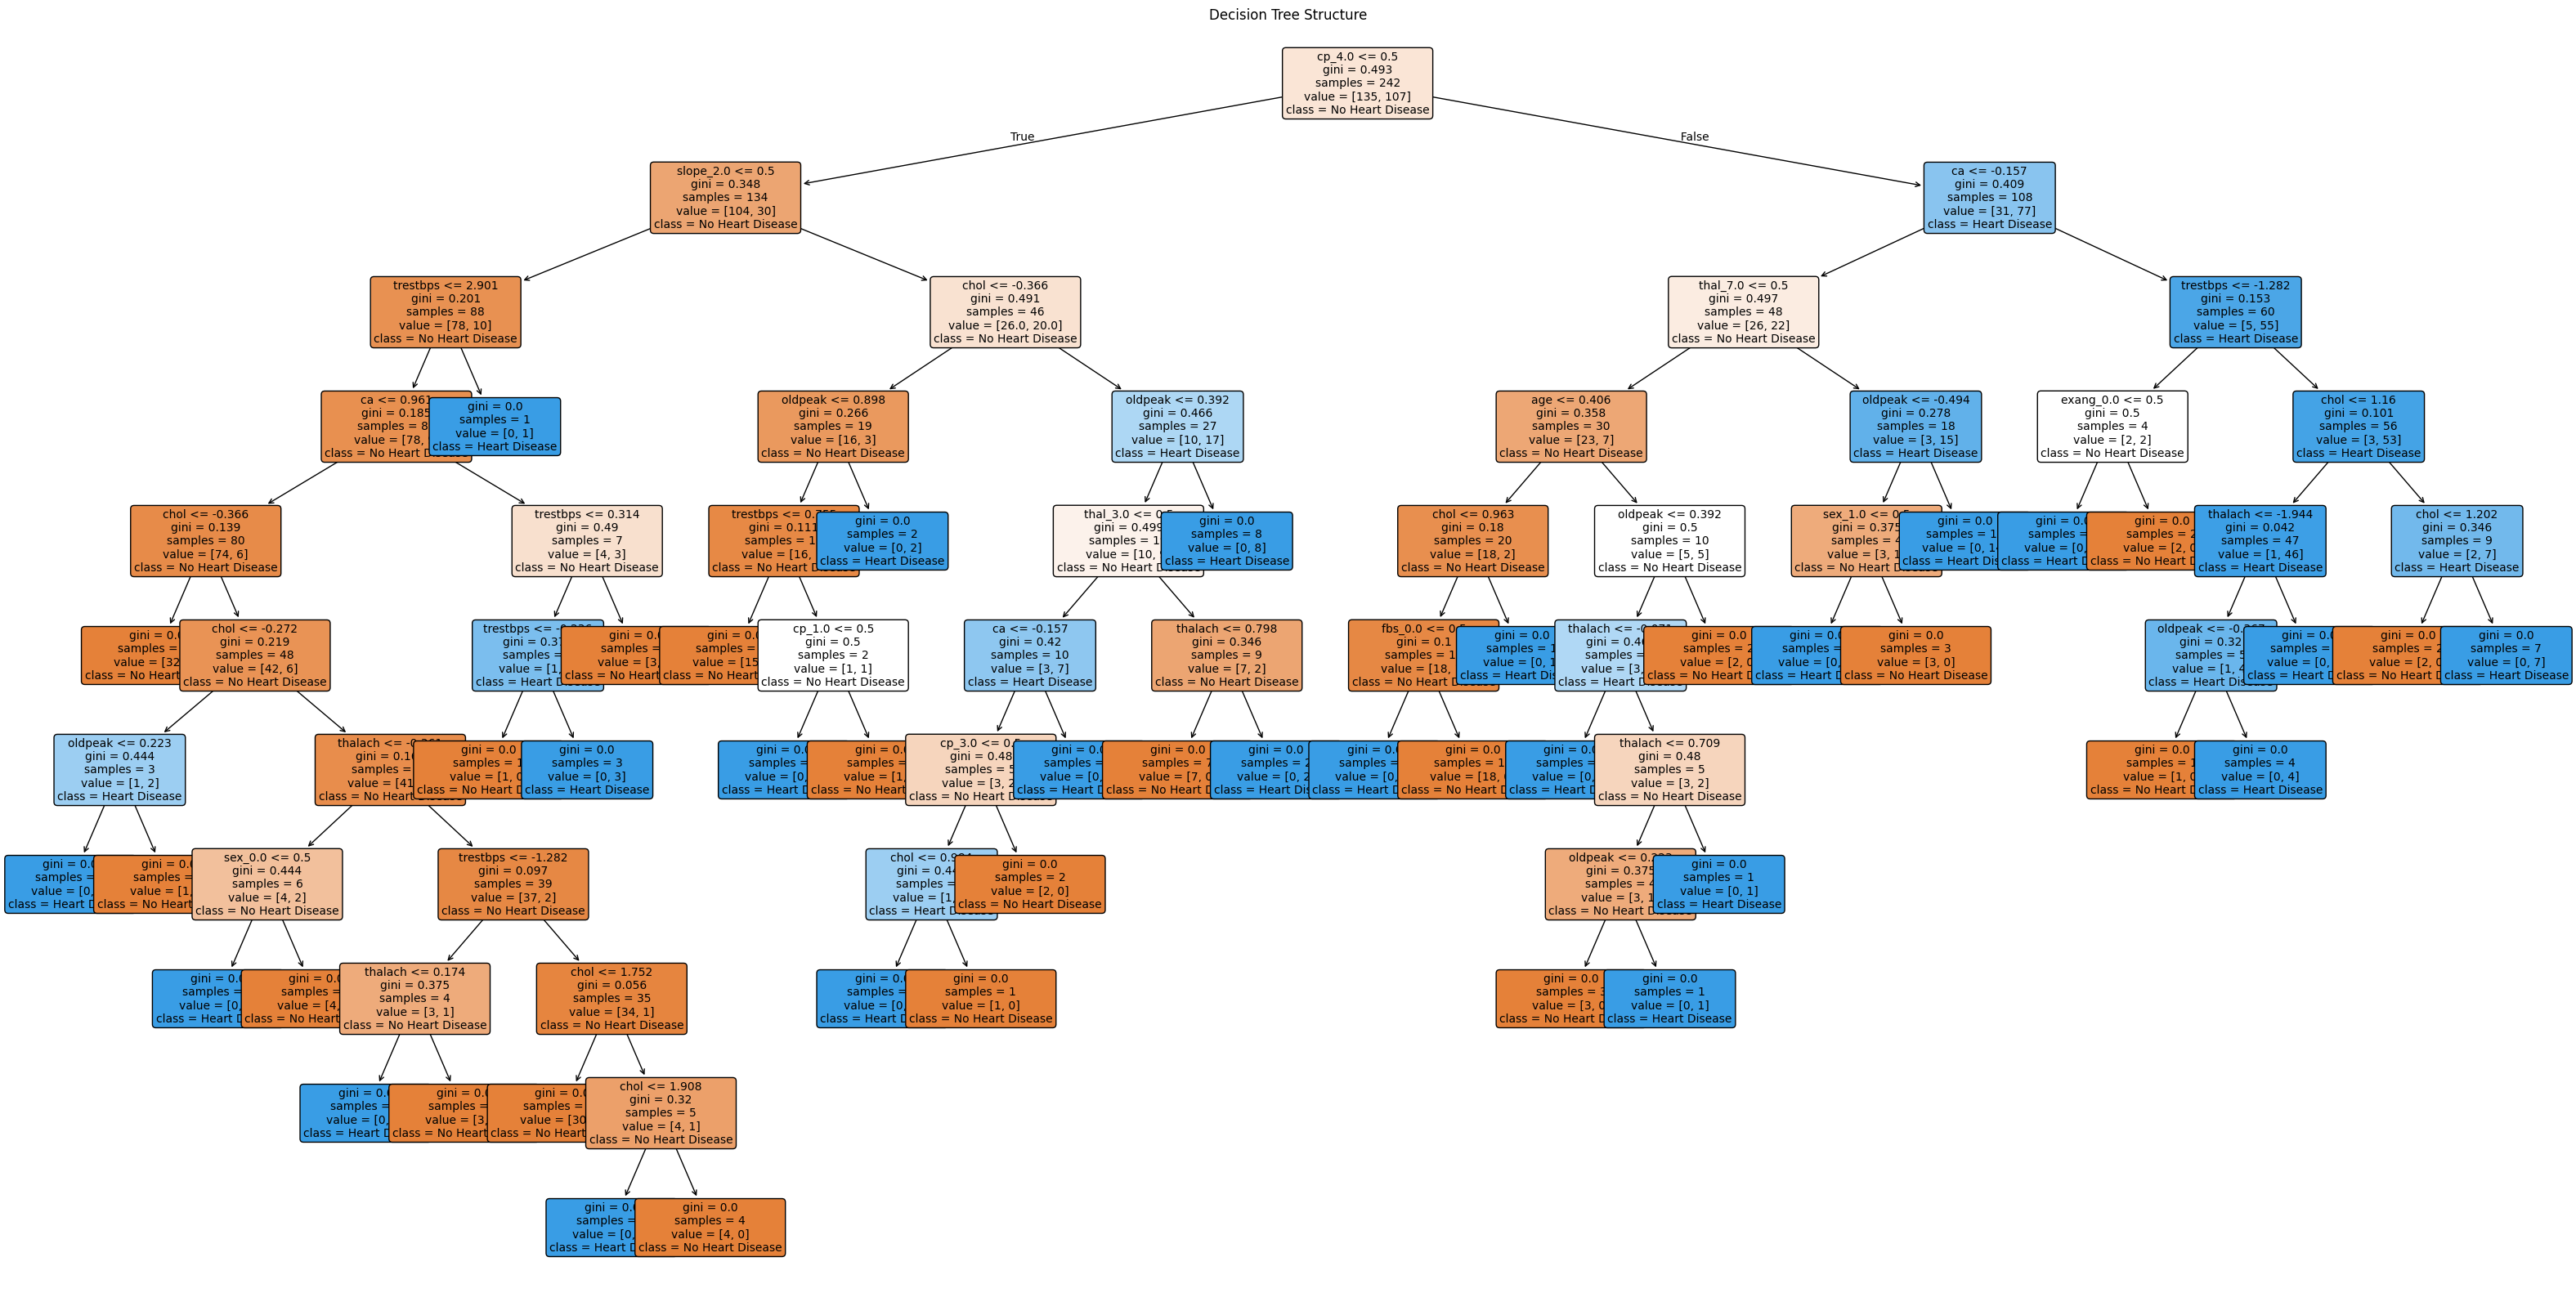

cp_4.0       0.239649
chol         0.135230
oldpeak      0.129607
ca           0.122408
thal_7.0     0.067850
thalach      0.067397
trestbps     0.064838
slope_2.0    0.052196
sex_0.0      0.022338
thal_3.0     0.018115
dtype: float64


In [ ]:
from sklearn.tree import plot_tree

tree_classifier = tree_pipeline.named_steps['classifier']
tree_feature_names = preprocessor.named_transformers_['num'].get_feature_names_out().tolist() + preprocessor.named_transformers_['cat'].get_feature_names_out().tolist()

plt.figure(figsize=(40, 20))
plot_tree(tree_classifier,
          feature_names=tree_feature_names,
          class_names=['No Heart Disease', 'Heart Disease'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('Decision Tree Structure')
plt.show()

importances = pd.Series(
    tree_classifier.feature_importances_,
    index=tree_feature_names
).sort_values(ascending=False)
print(importances.head(10))